# Lorenz System Identification

This notebook identifies Lorenz dynamics from one simulated trajectory.

**System:** $\dot{x} = \sigma(y - x)$, $\dot{y} = x(\rho - z) - y$, $\dot{z} = xy - \beta z$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from wias import build_weak_system, make_test_basis, CPQR_solver, solve_ode
from wias.utils import format_equation

## Define the library of candidate functions and ground truth coefficients

In [2]:
def lorenz_library(states):
    """Polynomial library up to degree 2 for Lorenz identification."""
    x_val = states[:, 0]
    y_val = states[:, 1]
    z_val = states[:, 2]

    columns = np.column_stack([
        np.ones_like(x_val),
        x_val,
        y_val,
        z_val,
        x_val**2,
        x_val * y_val,
        x_val * z_val,
        y_val**2,
        y_val * z_val,
        z_val**2,
    ])
    names = ["1", "x", "y", "z", "x^2", "xy", "xz", "y^2", "yz", "z^2"]
    return columns, names

# Define ground truth Lorenz system as coefficients in the library
# dx/dt = sigma(y - x)     = -sigma*x + sigma*y
# dy/dt = x(rho - z) - y   = rho*x - y - xz
# dz/dt = xy - beta*z      = xy - beta*z
sigma_true = 10.0
rho_true = 28.0
beta_true = 8.0 / 3.0

true_coefficients = {
    "x": np.array([0.0, -sigma_true, sigma_true, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]),
    "y": np.array([0.0, rho_true, -1.0, 0.0, 0.0, 0.0, -1.0, 0.0, 0.0, 0.0]),
    "z": np.array([0.0, 0.0, 0.0, -beta_true, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0]),
}

## Setup

Define system parameters and generate trajectories.

Initial condition (sampled from N(0,1)): [1, 1, 1]
Time span: 0.00 to 40.00
Samples per trajectory: 40001


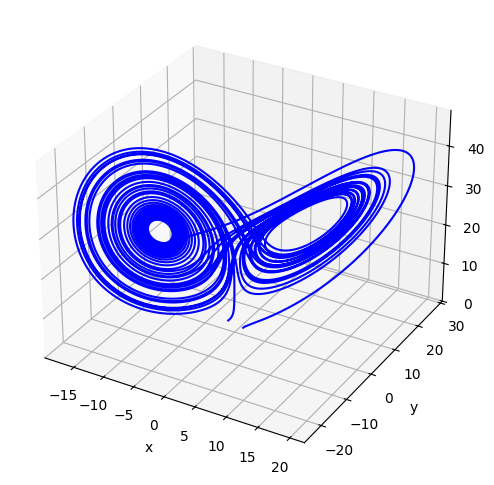

In [3]:
# Time discretization
time = np.linspace(0.0, 40.0, 40001)

initial_condition = [1,1,1]

# Generate trajectory using generic ODE solver with true coefficients
trajectory = solve_ode(lorenz_library, true_coefficients, initial_condition, time)

print(f"Initial condition (sampled from N(0,1)): {initial_condition}")
print(f"Time span: {time[0]:.2f} to {time[-1]:.2f}")
print(f"Samples per trajectory: {len(time)}")

# Plot trajectory
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection="3d")
ax.plot(trajectory[:, 0], trajectory[:, 1], trajectory[:, 2], color="blue")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
plt.show()

## Build Weak-Form System

Created 50 test functions


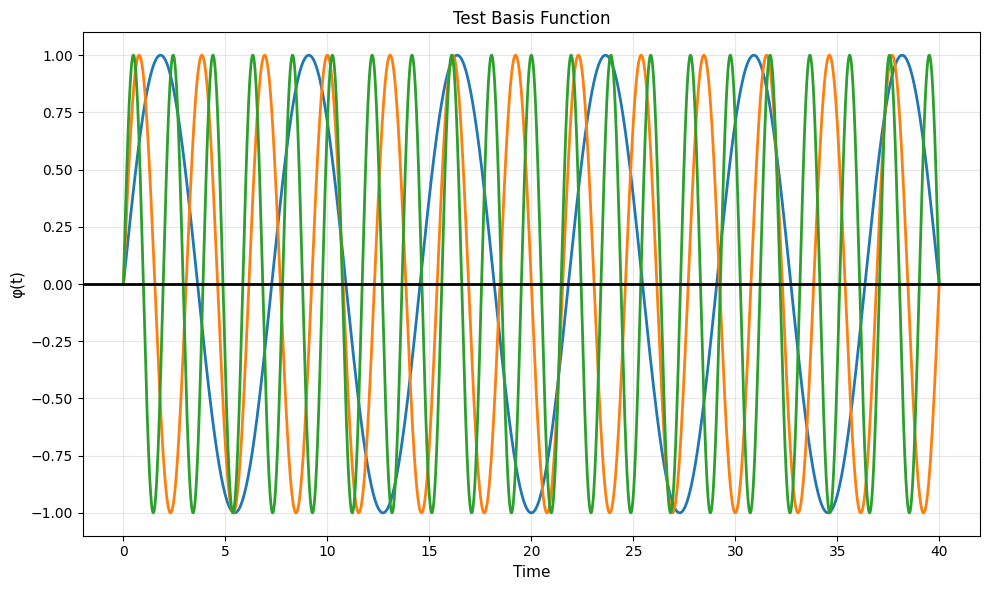

Test basis: 50 compactly supported functions

Library size: 10 terms
Library terms: ['1', 'x', 'y', 'z', 'x^2', 'xy', 'xz', 'y^2', 'yz', 'z^2']


In [4]:
# Create test basis
test_basis = make_test_basis(time, 50)
print(f"Created {len(test_basis)} test functions")

# Select indices to plot (first, middle, and last)
indices = [10, len(test_basis)//2, len(test_basis)-10]

plt.figure(figsize=(10, 6))
for idx in indices:
    phi, dphi = test_basis[idx]
    plt.plot(time, phi, linewidth=2)
   
    plt.ylabel('φ(t)', fontsize=11)
    plt.grid(True, alpha=0.3)

plt.title('Test Basis Function', fontsize=12)
plt.axhline(y=0, color='k', linestyle='-', linewidth=2)
plt.xlabel('Time', fontsize=11)
plt.tight_layout()
plt.show()

print(f'Test basis: {len(test_basis)} compactly supported functions')

# Get library names
names = lorenz_library(trajectory)[1]
print(f"\nLibrary size: {len(names)} terms")
print(f"Library terms: {names}")


## Solve for Coefficients

In [5]:
recovered = {}
for i, component in enumerate(["x", "y", "z"]):
    # Build weak system
    A, b = build_weak_system([trajectory], time, test_basis, lorenz_library, i)    
    recovered[component] = CPQR_solver(A, b)
    residual = np.linalg.norm(A @ recovered[component] - b)
    print(residual)

    for name, coeff, true_c in zip(names, recovered[component], true_coefficients[component]):
        print(f"  {name:6s}: {coeff:10.6f} (true {true_c:10.6f}, error {coeff - true_c:.3e})")


2.3878234657481726e-09
  1     :  -0.000000 (true   0.000000, error -3.025e-09)
  x     : -10.000000 (true -10.000000, error 1.329e-09)
  y     :  10.000000 (true  10.000000, error -3.027e-10)
  z     :   0.000000 (true   0.000000, error 3.256e-10)
  x^2   :  -0.000000 (true   0.000000, error -7.172e-11)
  xy    :  -0.000000 (true   0.000000, error -2.350e-11)
  xz    :  -0.000000 (true   0.000000, error -3.427e-11)
  y^2   :   0.000000 (true   0.000000, error 3.991e-11)
  yz    :  -0.000000 (true   0.000000, error -5.439e-12)
  z^2   :  -0.000000 (true   0.000000, error -3.104e-12)
4.02734520817337e-09
  1     :  -0.000000 (true   0.000000, error -5.191e-09)
  x     :  28.000000 (true  28.000000, error 5.244e-10)
  y     :  -1.000000 (true  -1.000000, error -1.542e-10)
  z     :   0.000000 (true   0.000000, error 7.189e-10)
  x^2   :   0.000000 (true   0.000000, error 2.485e-10)
  xy    :  -0.000000 (true   0.000000, error -2.567e-10)
  xz    :  -1.000000 (true  -1.000000, error -1.45

## Results


RECOVERED LORENZ EQUATIONS
x' = -10.000000*x + 10.000000*y
y' = 28.000000*x + -1.000000*y + -1.000000*xz
z' = -2.666667*z + 1.000000*xy


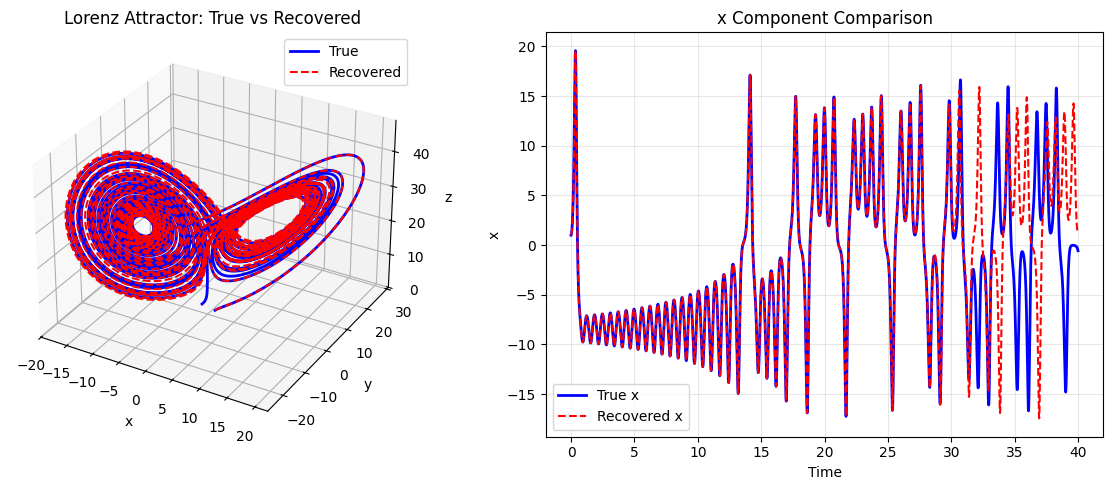

In [6]:
print("\n" + "="*60)
print("RECOVERED LORENZ EQUATIONS")
print("="*60)
print(format_equation("x", names, recovered["x"]))
print(format_equation("y", names, recovered["y"]))
print(format_equation("z", names, recovered["z"]))

# Integrate the recovered Lorenz system using generic solver
recovered_trajectory = solve_ode(lorenz_library, recovered, initial_condition, time)

# Plot original vs recovered trajectories
fig = plt.figure(figsize=(12, 5))

# 3D plot
ax1 = fig.add_subplot(121, projection="3d")
ax1.plot(trajectory[:, 0], trajectory[:, 1], trajectory[:, 2], 
         color="blue", label="True", linewidth=2)
ax1.plot(recovered_trajectory[:, 0], recovered_trajectory[:, 1], recovered_trajectory[:, 2], 
         color="red", linestyle="--", label="Recovered", linewidth=1.5)
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_zlabel("z")
ax1.legend()
ax1.set_title("Lorenz Attractor: True vs Recovered")

# Time series comparison
ax2 = fig.add_subplot(122)
ax2.plot(time, trajectory[:, 0], color="blue", label="True x", linewidth=2)
ax2.plot(time, recovered_trajectory[:, 0], color="red", linestyle="--", label="Recovered x", linewidth=1.5)
ax2.set_xlabel("Time")
ax2.set_ylabel("x")
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.set_title("x Component Comparison")

plt.tight_layout()
plt.show()